In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv


In [2]:
file_path = '/kaggle/input/datasets/tunguz/online-retail/Online_Retail.csv'
df = pd.read_csv(file_path, encoding = 'ISO-8859-1')
#df.shape
print(f"成功讀取！總共有{df.shape[0]}筆交易紀錄，{df.shape[1]}個欄位。")
df.head(5)

成功讀取！總共有541909筆交易紀錄，8個欄位。


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


退貨：(InvoiceNo 開頭為 C) & (Quantity < 0)

StockCode: Product (item) code. Nominal, a 5-digit integral number uniquely assigned to each distinct product.

In [3]:
special_codes_df = df[~df["StockCode"].astype(str).str.match(r'^\d{5}')]
special_codes_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
45,536370,POST,POSTAGE,3,12/1/10 8:45,18.00,12583.0,France
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527.0,United Kingdom
386,536403,POST,POSTAGE,1,12/1/10 11:27,15.00,12791.0,Netherlands
1123,536527,POST,POSTAGE,1,12/1/10 13:04,18.00,12662.0,Germany
1423,536540,C2,CARRIAGE,1,12/1/10 14:05,50.00,14911.0,EIRE
...,...,...,...,...,...,...,...,...
541540,581498,DOT,DOTCOM POSTAGE,1,12/9/11 10:26,1714.17,NaN,United Kingdom
541541,C581499,M,Manual,-1,12/9/11 10:28,224.69,15498.0,United Kingdom
541730,581570,POST,POSTAGE,1,12/9/11 11:59,18.00,12662.0,Germany
541767,581574,POST,POSTAGE,2,12/9/11 12:09,18.00,12526.0,Germany


In [4]:
special_codes_summary = special_codes_df.groupby("StockCode").agg(
    出現筆數 = ("InvoiceNo", "count"),
    商品描述 = ("Description", lambda x:list(x.dropna().unique()[:3]))
).sort_values(by='出現筆數', ascending=False)
special_codes_summary

,出現筆數,商品描述
StockCode,,
POST,1256,[POSTAGE]
DOT,710,[DOTCOM POSTAGE]
M,571,[Manual]
C2,144,[CARRIAGE]
D,77,[Discount]
S,63,[SAMPLES]
BANK CHARGES,37,[Bank Charges]
AMAZONFEE,34,[AMAZON FEE]
CRUK,16,[CRUK Commission]


In [5]:
non_product_codes = [
    "POST","DOT","M","C2","D","S",
    "BANK CHARGES","AMAZONFEE","CRUK",
    "B","m"
]

In [6]:
df_clean = df[(df["UnitPrice"]>0) & (~df["StockCode"].isin(non_product_codes))].copy()

df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["UnitPrice"]

In [7]:
is_return = (df_clean["InvoiceNo"].str.startswith("C")) & (df_clean["Quantity"]<0)
df_sales = df_clean[(~is_return) & (df_clean["Quantity"]>0)]
df_returns = df_clean[is_return]

In [8]:
df_sales

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/11 12:50,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/11 12:50,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/11 12:50,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/11 12:50,4.15,12680.0,France,16.60


In [9]:
df_returns

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/10 9:49,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/10 10:24,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom,-6.96
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/10 10:24,0.29,17548.0,United Kingdom,-6.96
...,...,...,...,...,...,...,...,...,...
540448,C581490,22178,VICTORIAN GLASS HANGING T-LIGHT,-12,12/9/11 9:57,1.95,14397.0,United Kingdom,-23.40
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/11 9:57,0.83,14397.0,United Kingdom,-9.13
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/11 11:57,10.95,15311.0,United Kingdom,-54.75
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/11 11:58,1.25,17315.0,United Kingdom,-1.25


In [10]:
print("=== 1. 筆數總量對帳（確保沒有資料憑空消失） ===")
print(f"清理後總筆數 (df_clean) : {len(df_clean)} 筆")
print(f"正向銷售筆數 (df_sales) : {len(df_sales)} 筆")
print(f"退貨樣本筆數 (df_returns): {len(df_returns)} 筆")
print(f"兩者相加是否等於總筆數？  : {len(df_sales) + len(df_returns) == len(df_clean)}")

=== 1. 筆數總量對帳（確保沒有資料憑空消失） ===
清理後總筆數 (df_clean) : 536496 筆
正向銷售筆數 (df_sales) : 527792 筆
退貨樣本筆數 (df_returns): 8704 筆
兩者相加是否等於總筆數？  : True


In [11]:
print("\n=== 2. 檢查 df_returns 條件是否 100% 精準 ===")
# 確認每一筆都是 C 開頭，且每一筆數量都是負數
all_start_c = df_returns['InvoiceNo'].str.startswith('C').all()
all_neg_qty = (df_returns['Quantity'] < 0).all()
print(f"全部 InvoiceNo 都以 'C' 開頭嗎？ : {all_start_c}")
print(f"全部 Quantity 都小於 0 嗎？       : {all_neg_qty}")


=== 2. 檢查 df_returns 條件是否 100% 精準 ===
全部 InvoiceNo 都以 'C' 開頭嗎？ : True
全部 Quantity 都小於 0 嗎？       : True


In [12]:
print("\n=== 3. 檢查 df_sales 條件是否 100% 精準 ===")
no_start_c = (~df_sales['InvoiceNo'].str.startswith('C')).all()
all_pos_qty = (df_sales['Quantity'] > 0).all()
print(f"完全沒有 'C' 開頭訂單嗎？        : {no_start_c}")
print(f"全部 Quantity 都大於 0 嗎？      : {all_pos_qty}")


=== 3. 檢查 df_sales 條件是否 100% 精準 ===
完全沒有 'C' 開頭訂單嗎？        : True
全部 Quantity 都大於 0 嗎？      : True


In [13]:
print("\n=== 4. 檢視退貨金額最大的前 5 筆極端紀錄 ===")
display(df_returns.sort_values(by='TotalPrice', ascending=True).head(5))


=== 4. 檢視退貨金額最大的前 5 筆極端紀錄 ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,12/9/11 9:27,2.08,16446.0,United Kingdom,-168469.6
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1/18/11 10:17,1.04,12346.0,United Kingdom,-77183.6
160145,C550456,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,4/18/11 13:08,2.10,15749.0,United Kingdom,-6539.4
160143,C550456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,-1930,4/18/11 13:08,2.55,15749.0,United Kingdom,-4921.5
160141,C550456,48185,DOORMAT FAIRY CAKE,-670,4/18/11 13:08,6.75,15749.0,United Kingdom,-4522.5


In [14]:
sales_by_item = df_sales.groupby("StockCode").agg(
    Description=('Description', 'first'),
    Sales_Qty=('Quantity', 'sum'),
    Sales_Revenue=('TotalPrice', 'sum')
).reset_index()
sales_by_item

,StockCode,Description,Sales_Qty,Sales_Revenue
0,10002,INFLATABLE POLITICAL GLOBE,860,759.89
1,10080,GROOVY CACTUS INFLATABLE,303,119.09
2,10120,DOGGY RUBBER,193,40.53
3,10123C,HEARTS WRAPPING TAPE,5,3.25
4,10124A,SPOTS ON RED BOOKCOVER TAPE,16,6.72
...,...,...,...,...
3908,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00,9,74.97
3909,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,10,167.05
3910,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,7,175.53
3911,gift_0001_40,Dotcomgiftshop Gift Voucher £40.00,3,100.70


In [15]:
returns_by_item = df_returns.groupby('StockCode').agg(
    Return_Qty=('Quantity', lambda x: abs(x.sum())),
    Return_Loss=('TotalPrice', lambda x: abs(x.sum()))
).reset_index()
returns_by_item

,StockCode,Return_Qty,Return_Loss
0,10133,10,4.20
1,10135,1,1.25
2,11001,185,237.05
3,15034,1385,108.29
4,15036,744,505.68
...,...,...,...
1933,90204,4,13.40
1934,90208,6,15.30
1935,90209A,6,12.60
1936,90209C,3,6.30


In [16]:
item_analysis = pd.merge(sales_by_item, returns_by_item, on="StockCode", how="left")
item_analysis["Return_Qty"] = item_analysis["Return_Qty"].fillna(0)
item_analysis["Return_Loss"] = item_analysis["Return_Loss"].fillna(0)

In [17]:
item_analysis["Return_Rate(%)"] = (item_analysis["Return_Qty"]/item_analysis["Sales_Qty"]*100).round(2)
item_analysis["Revenue_Loss_Ratio(%)"] = (item_analysis["Return_Loss"]/item_analysis["Sales_Revenue"]*100).round(2)

In [18]:
item_analysis[item_analysis["Return_Qty"]!=0]

,StockCode,Description,Sales_Qty,Sales_Revenue,Return_Qty,Return_Loss,Return_Rate(%),Revenue_Loss_Ratio(%)
7,10133,COLOURING PENCILS BROWN TUBE,2867,1544.22,10.0,4.20,0.35,0.27
8,10135,COLOURING PENCILS BROWN TUBE,2231,2207.39,1.0,1.25,0.04,0.06
9,11001,ASSTD DESIGN RACING CAR PEN,1615,2389.44,185.0,237.05,11.46,9.92
11,15034,PAPER POCKET TRAVELING FAN,6591,840.02,1385.0,108.29,21.01,12.89
12,15036,ASSORTED COLOURS SILK FAN,23826,18569.84,744.0,505.68,3.12,2.72
...,...,...,...,...,...,...,...,...
3859,90204,PAIR OF ENAMEL BUTTERFLY HAIRCLIP,29,96.86,4.0,13.40,13.79,13.83
3864,90208,PAIR OF PINK FLOWER CLUSTER SLIDE,53,132.70,6.0,15.30,11.32,11.53
3865,90209A,PURPLE ENAMEL+GLASS HAIR COMB,84,163.80,6.0,12.60,7.14,7.69
3867,90209C,PINK ENAMEL+GLASS HAIR COMB,263,480.50,3.0,6.30,1.14,1.31


若某商品整年只賣出 1 件、退貨 1 件，退貨率會高達 100%，但對公司毛利影響微乎其微。設定銷量門檻（例如：正向銷售總件數 >= 100），才能抓出真正造成營運痛點的高退貨商品。

In [19]:
top_return_items = item_analysis[item_analysis["Sales_Qty"]>=100].sort_values(
    by="Return_Rate(%)", ascending=False
)

In [20]:
print("=== 銷量 >= 100 件之高退貨率商品 Top 10 ===")
display(top_return_items.head(10))

=== 銷量 >= 100 件之高退貨率商品 Top 10 ===


,StockCode,Description,Sales_Qty,Sales_Revenue,Return_Qty,Return_Loss,Return_Rate(%),Revenue_Loss_Ratio(%)
2465,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,80995.0,168469.60,100.00,100.00
2942,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9476,26463.83,9376.0,321.60,98.94,1.22
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,74494.0,77479.64,95.46,94.83
3519,85232B,SET OF 3 BABUSHKA STACKING TINS,275,1361.25,255.0,1258.05,92.73,92.42
1967,23113,PANTRY CHOPPING BOARD,1154,5868.50,946.0,4803.06,81.98,81.84
3305,85023B,EAU DE NILE JEWELLED PHOTOFRAME,105,235.35,73.0,153.75,69.52,65.33
1916,23055,IVORY CHANDELIER T-LIGHT HOLDER,658,1401.43,432.0,690.72,65.65,49.29
1917,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,966,2916.87,579.0,1859.07,59.94,63.74
2671,47566B,TEA TIME PARTY BUNTING,2382,11290.12,1424.0,3692.95,59.78,32.71
1918,23057,GEMSTONE CHANDELIER T-LIGHT HOLDER,776,1783.52,433.0,636.15,55.80,35.67


In [21]:
sales_by_country = df_sales.groupby("Country").agg(
    Sales_Revenue=("TotalPrice","sum")
).reset_index()

In [22]:
returns_by_country = df_returns.groupby("Country").agg(
    Return_Loss=("TotalPrice", lambda x:abs(x.sum()))
).reset_index()

In [23]:
country_analysis = pd.merge(sales_by_country,returns_by_country,on="Country",how="left")
country_analysis["Return_Loss"] = country_analysis["Return_Loss"].fillna(0)
country_analysis["Revenue_Loss_Ratio(%)"] = (country_analysis["Return_Loss"]/country_analysis["Sales_Revenue"]*100).round(2)

In [24]:
country_analysis = country_analysis.sort_values(by="Revenue_Loss_Ratio(%)",ascending=False)
display(country_analysis)

,Country,Sales_Revenue,Return_Loss,Revenue_Loss_Ratio(%)
34,USA,3580.390,1849.47,51.66
2,Bahrain,754.140,205.74,27.28
8,Czech Republic,786.740,115.02,14.62
29,Saudi Arabia,145.920,14.75,10.11
31,Spain,55725.110,3959.91,7.11
20,Japan,37416.370,1996.58,5.34
36,United Kingdom,8748247.473,445843.38,5.10
32,Sweden,36839.330,1662.42,4.51
23,Malta,2070.590,90.12,4.35
10,EIRE,271164.300,11500.84,4.24


In [25]:
# 篩選具備一定營收規模的國家（例如正向銷售總營收 >= £5,000），避免極小市場干擾
major_countries = country_analysis[country_analysis['Sales_Revenue'] >= 5000].sort_values(
    by='Revenue_Loss_Ratio(%)', ascending=False
)

print("=== 主要銷售國家（營收 >= £5,000）退貨金額損失佔比排行 ===")
display(major_countries)

=== 主要銷售國家（營收 >= £5,000）退貨金額損失佔比排行 ===


,Country,Sales_Revenue,Return_Loss,Revenue_Loss_Ratio(%)
31,Spain,55725.110,3959.91,7.11
20,Japan,37416.370,1996.58,5.34
36,United Kingdom,8748247.473,445843.38,5.10
32,Sweden,36839.330,1662.42,4.51
10,EIRE,271164.300,11500.84,4.24
19,Italy,15820.240,543.90,3.44
18,Israel,8135.260,227.44,2.80
7,Cyprus,13254.690,323.40,2.44
14,Germany,205569.890,4761.49,2.32
26,Poland,6974.650,121.51,1.74


In [26]:
# 2. 客戶維度分析 (CustomerID)：抓出惡意頻繁退貨客與巨額取消訂單批發商
# ==========================================
# 客戶維度必須排除 CustomerID 為空值的訪客紀錄
df_sales_cust = df_sales.dropna(subset=['CustomerID']).copy()
df_returns_cust = df_returns.dropna(subset=['CustomerID']).copy()

In [27]:
df_sales_cust['CustomerID'] = df_sales_cust['CustomerID'].astype(int)
df_returns_cust['CustomerID'] = df_returns_cust['CustomerID'].astype(int)

In [28]:
sales_by_cust = df_sales_cust.groupby(['CustomerID', 'Country']).agg(
    Sales_Orders=('InvoiceNo', 'nunique'),
    Sales_Qty=('Quantity', 'sum'),
    Sales_Revenue=('TotalPrice', 'sum')
).reset_index()

In [29]:
returns_by_cust = df_returns_cust.groupby('CustomerID').agg(
    Return_Orders=('InvoiceNo', 'nunique'),
    Return_Qty=('Quantity', lambda x: abs(x.sum())),
    Return_Loss=('TotalPrice', lambda x: abs(x.sum()))
).reset_index()

In [30]:
cust_analysis = pd.merge(sales_by_cust, returns_by_cust, on='CustomerID', how='left').fillna(0)
cust_analysis['Cust_Return_Rate(%)'] = (
    cust_analysis['Return_Qty'] / cust_analysis['Sales_Qty'] * 100
).round(2)
cust_analysis['Cust_Loss_Ratio(%)'] = (
    cust_analysis['Return_Loss'] / cust_analysis['Sales_Revenue'] * 100
).round(2)

In [31]:
print("\n=== 類型 A：退貨金額損失最高的 Top 10 客戶（常為大額取消訂單之批發商） ===")
display(cust_analysis.sort_values(by='Return_Loss', ascending=False).head(10))


=== 類型 A：退貨金額損失最高的 Top 10 客戶（常為大額取消訂單之批發商） ===


,CustomerID,Country,Sales_Orders,Sales_Qty,Sales_Revenue,Return_Orders,Return_Qty,Return_Loss,Cust_Return_Rate(%),Cust_Loss_Ratio(%)
3014,16446,United Kingdom,2,80997,168472.50,1.0,80995.0,168469.60,100.00,100.00
0,12346,United Kingdom,1,74215,77183.60,1.0,74215.0,77183.60,100.00,100.00
2510,15749,United Kingdom,3,18028,44534.30,1.0,9014.0,22998.40,50.00,51.64
2708,16029,United Kingdom,62,40207,72882.09,4.0,8004.0,14688.24,19.91,20.15
461,12931,United Kingdom,15,28004,42055.96,4.0,4427.0,8511.15,15.81,20.24
1887,14911,EIRE,198,80179,136275.72,44.0,3331.0,7393.59,4.15,5.43
1670,14607,United Kingdom,12,10734,15021.50,3.0,3768.0,5228.40,35.10,34.81
3733,17450,United Kingdom,46,69993,194550.79,3.0,952.0,4815.26,1.36,2.48
4097,17949,United Kingdom,44,30450,58030.48,5.0,2878.0,4814.74,9.45,8.30
2309,15482,United Kingdom,11,5019,11014.96,4.0,2022.0,4486.24,40.29,40.73


In [32]:
print("\n=== 類型 B：退貨訂單次數最多的 Top 10 客戶（高頻率退貨帳號） ===")
display(cust_analysis.sort_values(by='Return_Orders', ascending=False).head(10))


=== 類型 B：退貨訂單次數最多的 Top 10 客戶（高頻率退貨帳號） ===


,CustomerID,Country,Sales_Orders,Sales_Qty,Sales_Revenue,Return_Orders,Return_Qty,Return_Loss,Cust_Return_Rate(%),Cust_Loss_Ratio(%)
4015,17841,United Kingdom,124,23053,40967.72,45.0,203.0,634.50,0.88,1.55
1887,14911,EIRE,198,80179,136275.72,44.0,3331.0,7393.59,4.15,5.43
1669,14606,United Kingdom,90,6214,12006.65,35.0,245.0,439.55,3.94,3.66
2184,15311,United Kingdom,91,38194,60767.90,27.0,474.0,1348.56,1.24,2.22
570,13089,United Kingdom,97,31070,58825.83,21.0,283.0,1439.95,0.91,2.45
899,13534,United Kingdom,25,2961,5870.08,18.0,85.0,257.00,2.87,4.38
108,12471,Germany,27,8104,17424.05,18.0,246.0,1065.13,3.04,6.11
563,13078,United Kingdom,26,5630,12627.94,17.0,73.0,195.66,1.30,1.55
1061,13767,United Kingdom,37,7322,17220.36,15.0,64.0,274.65,0.87,1.59
589,13113,United Kingdom,24,3045,12245.96,15.0,449.0,1722.31,14.75,14.06


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

圖表 1：熱銷商品退貨率 Top 10 橫向長條圖

篩選正向銷售 >= 100 件的商品，取退貨率前 10 名

In [34]:
top10_items = top_return_items.head(10).copy()
display(top10_items)

,StockCode,Description,Sales_Qty,Sales_Revenue,Return_Qty,Return_Loss,Return_Rate(%),Revenue_Loss_Ratio(%)
2465,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,80995.0,168469.60,100.00,100.00
2942,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9476,26463.83,9376.0,321.60,98.94,1.22
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,74494.0,77479.64,95.46,94.83
3519,85232B,SET OF 3 BABUSHKA STACKING TINS,275,1361.25,255.0,1258.05,92.73,92.42
1967,23113,PANTRY CHOPPING BOARD,1154,5868.50,946.0,4803.06,81.98,81.84
3305,85023B,EAU DE NILE JEWELLED PHOTOFRAME,105,235.35,73.0,153.75,69.52,65.33
1916,23055,IVORY CHANDELIER T-LIGHT HOLDER,658,1401.43,432.0,690.72,65.65,49.29
1917,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,966,2916.87,579.0,1859.07,59.94,63.74
2671,47566B,TEA TIME PARTY BUNTING,2382,11290.12,1424.0,3692.95,59.78,32.71
1918,23057,GEMSTONE CHANDELIER T-LIGHT HOLDER,776,1783.52,433.0,636.15,55.80,35.67


/tmp/ipykernel_16/763072050.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


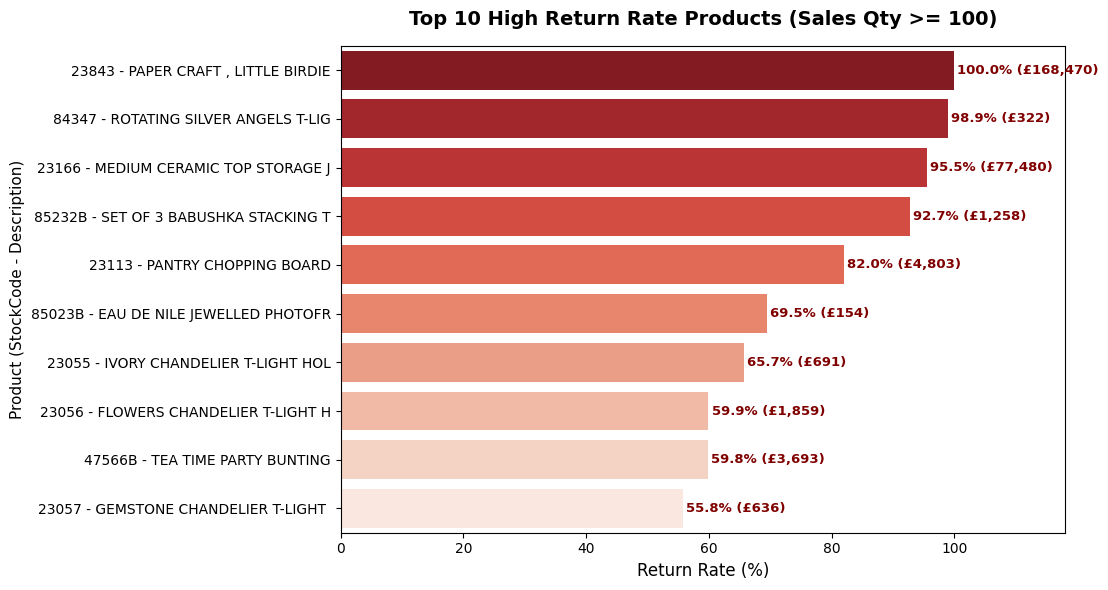

In [35]:
# 組合「貨號 + 縮短品名」作為 Y 軸標籤，避免標籤過長擠壓圖表
top10_items['Label'] = top10_items['StockCode'].astype(str) + ' - ' + top10_items['Description'].astype(str).str[:28]

plt.figure(figsize=(11, 6))
ax1 = sns.barplot(
    data=top10_items,
    x='Return_Rate(%)',
    y='Label',
    palette='Reds_r'
)

plt.title('Top 10 High Return Rate Products (Sales Qty >= 100)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Return Rate (%)', fontsize=12)
plt.ylabel('Product (StockCode - Description)', fontsize=11)
plt.xlim(0, top10_items['Return_Rate(%)'].max() * 1.18)

# 在長條右側標註精確退貨率與損失金額
for index, row in enumerate(top10_items.itertuples()):
    ax1.text(
        row._7 + 0.5,  # Return_Rate(%) 欄位位置，若欄位順序不同可改用 getattr(row, '_7') 或直接用 iloc
        index,
        f"{row._7:.1f}% (£{row.Return_Loss:,.0f})",
        va='center', fontsize=9.5, fontweight='bold', color='#800000'
    )

plt.tight_layout()
plt.savefig('top_returned_products.png', dpi=300, bbox_inches='tight')
plt.show()

圖表 2：商品銷量 vs. 退貨率四象限散點圖

聚焦於正向銷售 >= 50 件且有退貨紀錄的商品，觀察核心營運區間

In [36]:
quad_df = item_analysis[(item_analysis['Sales_Qty'] >= 50) & (item_analysis['Return_Qty'] > 0)].copy()
quad_df

,StockCode,Description,Sales_Qty,Sales_Revenue,Return_Qty,Return_Loss,Return_Rate(%),Revenue_Loss_Ratio(%)
7,10133,COLOURING PENCILS BROWN TUBE,2867,1544.22,10.0,4.20,0.35,0.27
8,10135,COLOURING PENCILS BROWN TUBE,2231,2207.39,1.0,1.25,0.04,0.06
9,11001,ASSTD DESIGN RACING CAR PEN,1615,2389.44,185.0,237.05,11.46,9.92
11,15034,PAPER POCKET TRAVELING FAN,6591,840.02,1385.0,108.29,21.01,12.89
12,15036,ASSORTED COLOURS SILK FAN,23826,18569.84,744.0,505.68,3.12,2.72
...,...,...,...,...,...,...,...,...
3852,90201B,BLACK ENAMEL FLOWER RING,86,252.90,7.0,20.65,8.14,8.17
3853,90201C,RED ENAMEL FLOWER RING,63,185.42,6.0,17.70,9.52,9.55
3864,90208,PAIR OF PINK FLOWER CLUSTER SLIDE,53,132.70,6.0,15.30,11.32,11.53
3865,90209A,PURPLE ENAMEL+GLASS HAIR COMB,84,163.80,6.0,12.60,7.14,7.69


In [37]:
# 排除極端批發單一事件離群值（如退貨率 > 80% 且銷量破萬的特殊個案），讓四象限分布更清晰
quad_df_plot = quad_df[quad_df['Return_Rate(%)'] <= 60].copy()
quad_df_plot

,StockCode,Description,Sales_Qty,Sales_Revenue,Return_Qty,Return_Loss,Return_Rate(%),Revenue_Loss_Ratio(%)
7,10133,COLOURING PENCILS BROWN TUBE,2867,1544.22,10.0,4.20,0.35,0.27
8,10135,COLOURING PENCILS BROWN TUBE,2231,2207.39,1.0,1.25,0.04,0.06
9,11001,ASSTD DESIGN RACING CAR PEN,1615,2389.44,185.0,237.05,11.46,9.92
11,15034,PAPER POCKET TRAVELING FAN,6591,840.02,1385.0,108.29,21.01,12.89
12,15036,ASSORTED COLOURS SILK FAN,23826,18569.84,744.0,505.68,3.12,2.72
...,...,...,...,...,...,...,...,...
3852,90201B,BLACK ENAMEL FLOWER RING,86,252.90,7.0,20.65,8.14,8.17
3853,90201C,RED ENAMEL FLOWER RING,63,185.42,6.0,17.70,9.52,9.55
3864,90208,PAIR OF PINK FLOWER CLUSTER SLIDE,53,132.70,6.0,15.30,11.32,11.53
3865,90209A,PURPLE ENAMEL+GLASS HAIR COMB,84,163.80,6.0,12.60,7.14,7.69


In [38]:
avg_sales = quad_df_plot["Sales_Qty"].median()
avg_return = quad_df_plot["Return_Rate(%)"].median()

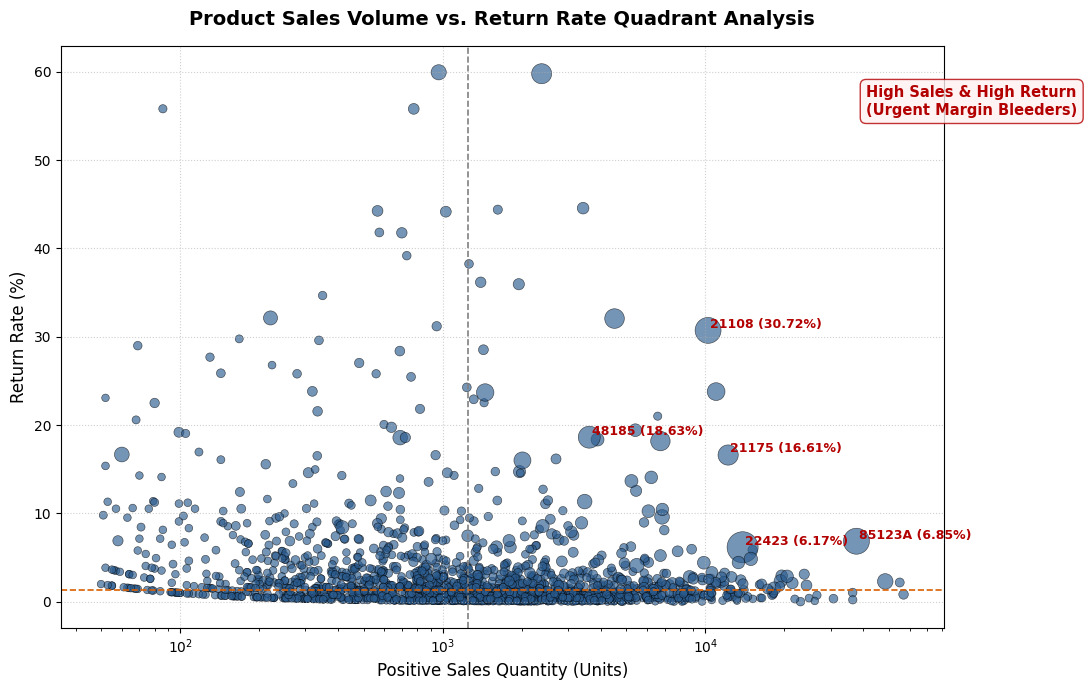

In [39]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=quad_df_plot,
    x='Sales_Qty',
    y='Return_Rate(%)',
    size='Return_Loss',
    sizes=(30, 500),
    alpha=0.65,
    color='#2b5c8f',
    edgecolor='black',
    legend=False
)
# 畫出四象限中位數分割線
plt.axvline(avg_sales, color='gray', linestyle='--', linewidth=1.2)
plt.axhline(avg_return, color='#d95f02', linestyle='--', linewidth=1.2)

# 標註右上象限（高銷量 × 高退貨率）的重點出血商品
priority_items = quad_df_plot[
    (quad_df_plot['Sales_Qty'] > avg_sales) & (quad_df_plot['Return_Rate(%)'] > avg_return)
].sort_values(by='Return_Loss', ascending=False).head(5)

for _, r in priority_items.iterrows():
    plt.text(
        r['Sales_Qty'] * 1.02,
        r['Return_Rate(%)'] + 0.3,
        f"{r['StockCode']} ({r['Return_Rate(%)']}%)",
        fontsize=9, fontweight='bold', color='#b30000'
    )

# 加上象限說明文字框
plt.text(
    quad_df_plot['Sales_Qty'].max() * 0.72,
    quad_df_plot['Return_Rate(%)'].max() * 0.92,
    'High Sales & High Return\n(Urgent Margin Bleeders)',
    fontsize=10.5, fontweight='bold', color='#b30000',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#fff0f0', edgecolor='#b30000', alpha=0.8)
)

plt.title('Product Sales Volume vs. Return Rate Quadrant Analysis', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Positive Sales Quantity (Units)', fontsize=12)
plt.ylabel('Return Rate (%)', fontsize=12)
plt.xscale('log')  # 使用對數刻度讓銷量分布更均勻易讀
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('return_quadrant_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

圖表 3：前十大營收國家退貨金額損失佔比對比圖

In [40]:
top10_countries = country_analysis.sort_values(by='Sales_Revenue', ascending=False).head(10).sort_values(
    by='Revenue_Loss_Ratio(%)', ascending=False
)
top10_countries

,Country,Sales_Revenue,Return_Loss,Revenue_Loss_Ratio(%)
31,Spain,55725.110,3959.91,7.11
20,Japan,37416.370,1996.58,5.34
36,United Kingdom,8748247.473,445843.38,5.10
10,EIRE,271164.300,11500.84,4.24
14,Germany,205569.890,4761.49,2.32
13,France,184582.740,2419.35,1.31
33,Switzerland,53087.900,582.55,1.10
0,Australia,138171.310,1181.31,0.85
3,Belgium,36927.340,264.38,0.72
24,Netherlands,283889.340,409.80,0.14


In [41]:
# 計算全站整體退貨金額損失佔比作為基準線
overall_loss_ratio = (df_returns['TotalPrice'].abs().sum() / df_sales['TotalPrice'].sum()) * 100

/tmp/ipykernel_16/2121192154.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(


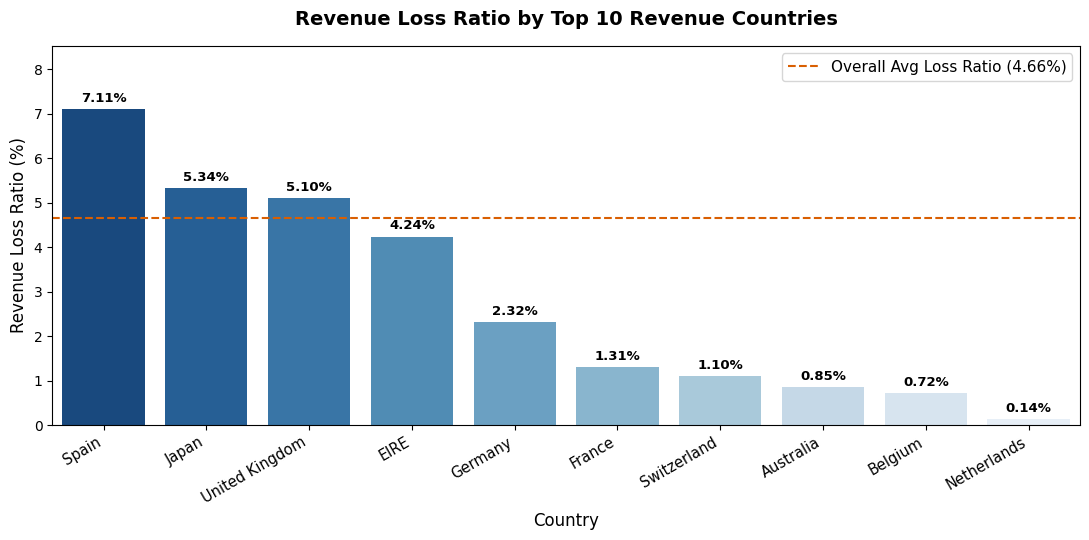

In [42]:
plt.figure(figsize=(11, 5.5))
ax3 = sns.barplot(
    data=top10_countries,
    x='Country',
    y='Revenue_Loss_Ratio(%)',
    palette='Blues_r'
)

# 加上全站平均損失率紅線
plt.axhline(overall_loss_ratio, color='#d95f02', linestyle='--', linewidth=1.5, label=f'Overall Avg Loss Ratio ({overall_loss_ratio:.2f}%)')

plt.title('Revenue Loss Ratio by Top 10 Revenue Countries', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Revenue Loss Ratio (%)', fontsize=12)
plt.xticks(rotation=30, ha='right', fontsize=10.5)
plt.ylim(0, top10_countries['Revenue_Loss_Ratio(%)'].max() * 1.2)
plt.legend(fontsize=11)

# 在每根長條上方標註百分比
for rect in ax3.patches:
    height = rect.get_height()
    ax3.annotate(
        f'{height:.2f}%',
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 3), textcoords='offset points',
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

plt.tight_layout()
plt.savefig('country_return_loss_ratio.png', dpi=300, bbox_inches='tight')
plt.show()